In [3]:
import math
import numpy as np
import matplotlib.pyplot as plt

SEED = 12345
N_PER_CLASS = 1000
K = 3

# Mixture weights and means for the two classes
PI = {
    0: [0.40, 0.35, 0.25],
    1: [0.30, 0.40, 0.30]
}

MU = {
    0: [[-4, -2], [0, 3], [4, -1]],
    1: [[-3, 3], [1, -3], [5, 3]]
}

# Covariance matrices
C = {
    "spherical": [
        [[1, 0], [0, 1]],
        [[1, 0], [0, 1]],
        [[1, 0], [0, 1]]
    ],
    "diagonal": [
        [[2, 0], [0, 0.5]],
        [[0.5, 0], [0, 2]],
        [[1.5, 0], [0, 0.7]]
    ],
    "full": [
        [[2, 0.8], [0.8, 1]],
        [[1.5, -0.6], [-0.6, 1]],
        [[1, 0.5], [0.5, 1.5]]
    ]
}

In [4]:
# CELL 3: Manual LCG
seed = SEED

def uniform():
    global seed
    seed = (1664525 * seed + 1013904223) % (2**32)
    return seed / (2**32)


# Box-Muller: two standard normal values
def box_muller():
    u1 = uniform()
    u2 = uniform()

    while u1 == 0:
        u1 = uniform()

    r = math.sqrt(-2 * math.log(u1))

    return (
        r * math.cos(2 * math.pi * u2),
        r * math.sin(2 * math.pi * u2)
    )


print(box_muller())


(2.7749468446396195, 0.28956428520256783)


In [5]:
# CELL 4: Generate data
# For C = [[a, b], [b, c]]:
# x = mu + Lz, using manual Cholesky formula

def generate_point(mean, cov):
    z1, z2 = box_muller()

    a, b, c = cov[0][0], cov[0][1], cov[1][1]

    x = mean[0] + math.sqrt(a) * z1
    y = mean[1] + (b / math.sqrt(a)) * z1 \
        + math.sqrt(c - b * b / a) * z2

    return np.array([x, y])


def generate_class(cls, case):
    X = np.zeros((N_PER_CLASS, 2))
    comp = np.zeros(N_PER_CLASS, dtype=int)

    for n in range(N_PER_CLASS):
        u = uniform()

        if u < PI[cls][0]:
            i = 0
        elif u < PI[cls][0] + PI[cls][1]:
            i = 1
        else:
            i = 2

        X[n] = generate_point(MU[cls][i], C[case][i])
        comp[n] = i

    return X, comp


DATA = {}

for case in C:
    seed = SEED
    DATA[case] = {
        c: generate_class(c, case) for c in (0, 1)
    }

    print(
        case,
        DATA[case][0][0].shape,
        DATA[case][1][0].shape
    )


spherical (1000, 2) (1000, 2)
diagonal (1000, 2) (1000, 2)
full (1000, 2) (1000, 2)


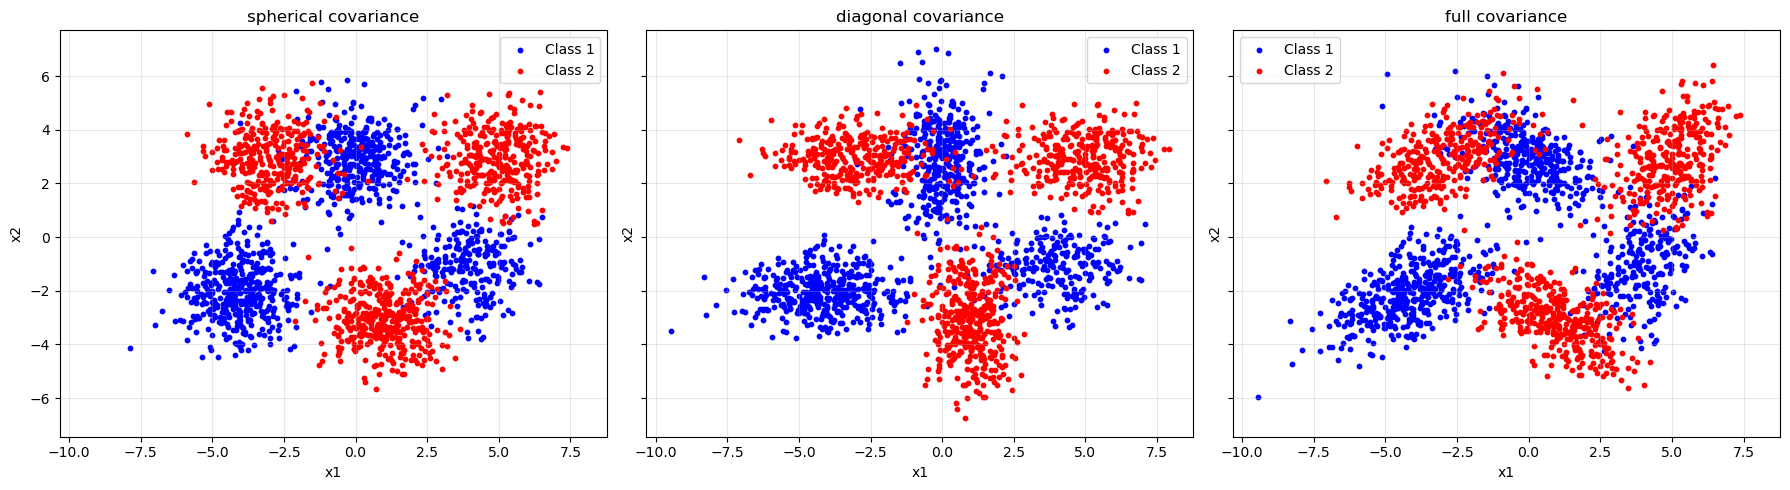

In [6]:
# CELL 5: Plot generated data
fig, axes = plt.subplots(
    1, 3, figsize=(18, 5), sharex=True, sharey=True
)

for ax, case in zip(axes, DATA):
    ax.scatter(
        DATA[case][0][0][:, 0],
        DATA[case][0][0][:, 1],
        s=10, c="blue", label="Class 1"
    )

    ax.scatter(
        DATA[case][1][0][:, 0],
        DATA[case][1][0][:, 1],
        s=10, c="red", label="Class 2"
    )

    ax.set_title(case + " covariance")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [7]:
# CELL 6: 80/20 split per class
n_train = int(0.8 * N_PER_CLASS)

TRAIN = {}
TEST = {}

for case in DATA:
    TRAIN[case] = {
        c: DATA[case][c][0][:n_train] for c in (0, 1)
    }

    TEST[case] = {
        c: DATA[case][c][0][n_train:] for c in (0, 1)
    }

    print(
        case,
        "train:", TRAIN[case][0].shape,
        "test:", TEST[case][0].shape
    )


spherical train: (800, 2) test: (200, 2)
diagonal train: (800, 2) test: (200, 2)
full train: (800, 2) test: (200, 2)


In [8]:
# CELL 7: K-means implementation
def kmeans(X, K, max_iter=100):
    centroids = X[:K].copy()

    for iteration in range(max_iter):
        distances = (
            (X[:, None, :] - centroids[None, :, :]) ** 2
        ).sum(axis=2)

        labels = distances.argmin(axis=1)

        new_centroids = centroids.copy()

        for k in range(K):
            points = X[labels == k]

            if len(points) > 0:
                new_centroids[k] = points.mean(axis=0)

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    distances = (
        (X[:, None, :] - centroids[None, :, :]) ** 2
    ).sum(axis=2)

    labels = distances.argmin(axis=1)

    return centroids, labels

In [9]:
# CELL 8: Run K-means on training data
CENTROIDS = {}
LABELS = {}

for case in TRAIN:
    CENTROIDS[case] = {}
    LABELS[case] = {}

    for c in (0, 1):
        CENTROIDS[case][c], LABELS[case][c] = kmeans(
            TRAIN[case][c], K
        )

    print(case)

    for c in (0, 1):
        print(
            "  class", c,
            "centroids:",
            np.round(CENTROIDS[case][c], 2).tolist()
        )

        print("  class", c, "designed means:", MU[c])

spherical
  class 0 centroids: [[-4.12, -2.0], [4.0, -1.04], [-0.03, 2.89]]
  class 0 designed means: [[-4, -2], [0, 3], [4, -1]]
  class 1 centroids: [[0.96, -3.09], [4.94, 2.9], [-2.99, 2.93]]
  class 1 designed means: [[-3, 3], [1, -3], [5, 3]]
diagonal
  class 0 centroids: [[-4.16, -1.99], [-0.02, 2.85], [4.0, -1.03]]
  class 0 designed means: [[-4, -2], [0, 3], [4, -1]]
  class 1 centroids: [[0.97, -3.12], [4.91, 2.91], [-3.02, 2.95]]
  class 1 designed means: [[-3, 3], [1, -3], [5, 3]]
full
  class 0 centroids: [[-4.21, -2.09], [3.97, -0.98], [-0.11, 2.91]]
  class 0 designed means: [[-4, -2], [0, 3], [4, -1]]
  class 1 centroids: [[0.95, -3.05], [4.93, 2.88], [-3.02, 2.94]]
  class 1 designed means: [[-3, 3], [1, -3], [5, 3]]


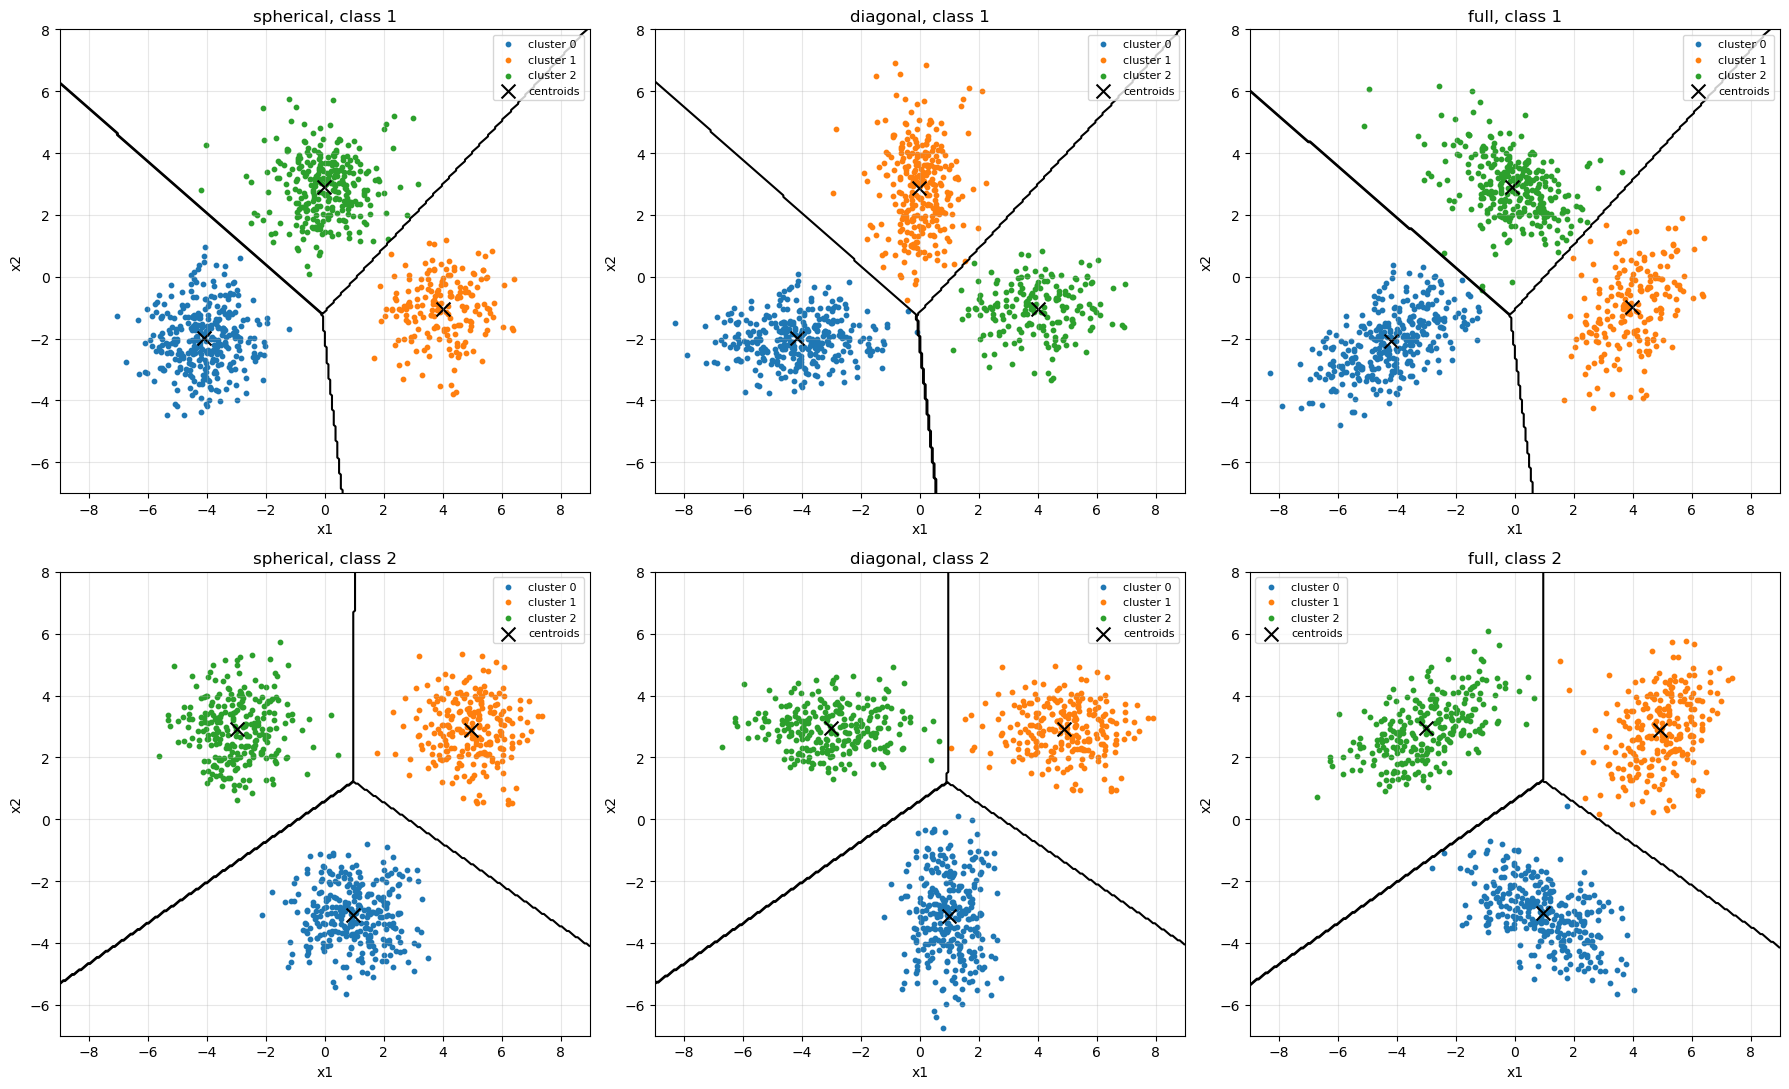

In [11]:
# CELL 9: Clusters and boundaries
cluster_colors = ["tab:blue", "tab:orange", "tab:green"]

xs = np.linspace(-9, 9, 300)
ys = np.linspace(-7, 8, 300)

xx, yy = np.meshgrid(xs, ys)
grid = np.stack([xx.ravel(), yy.ravel()], axis=1)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for col, case in enumerate(TRAIN):
    for c in (0, 1):
        ax = axes[c, col]

        X = TRAIN[case][c]
        cent = CENTROIDS[case][c]

        d = (
            (grid[:, None, :] - cent[None, :, :]) ** 2
        ).sum(axis=2)

        grid_labels = d.argmin(axis=1).reshape(xx.shape)

        for k in range(K):
            ax.scatter(
                X[LABELS[case][c] == k, 0],
                X[LABELS[case][c] == k, 1],
                s=10,
                c=cluster_colors[k],
                label="cluster " + str(k)
            )

        ax.scatter(
            cent[:, 0], cent[:, 1],
            c="k", marker="x", s=100,
            label="centroids"
        )

        ax.contour(
            xx, yy, grid_labels,
            levels=[0.5, 1.5], colors="k"
        )

        ax.set_title(case + ", class " + str(c + 1))
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [12]:
# CELL 10: Predict test classes
PRED = {}

for case in TEST:
    PRED[case] = {}

    for c in (0, 1):
        X = TEST[case][c]
        distortion = []

        for cls in (0, 1):
            d = (
                (X[:, None, :] -
                 CENTROIDS[case][cls][None, :, :]) ** 2
            ).sum(axis=2)

            distortion.append(d.min(axis=1))

        distortion = np.stack(distortion, axis=1)
        PRED[case][c] = distortion.argmin(axis=1)

In [13]:
# CELL 11: Accuracy
for case in PRED:
    correct0 = int(np.sum(PRED[case][0] == 0))
    correct1 = int(np.sum(PRED[case][1] == 1))

    total = len(PRED[case][0]) + len(PRED[case][1])

    print(
        case + ": class 0 " +
        str(correct0) + "/" + str(len(PRED[case][0])) +
        ", class 1 " +
        str(correct1) + "/" + str(len(PRED[case][1])) +
        ", overall " +
        str(round((correct0 + correct1) / total, 3))
    )

spherical: class 0 184/200, class 1 190/200, overall 0.935
diagonal: class 0 185/200, class 1 181/200, overall 0.915
full: class 0 177/200, class 1 185/200, overall 0.905
